# Job Offer Acceptance Prediction: Exploratory Data Analysis (EDA)


In [14]:
# 1. Import Libraries
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.preprocessing import LabelEncoder
from sklearn.feature_selection import SelectKBest, f_classif
from sklearn.ensemble import RandomForestClassifier

import warnings
warnings.filterwarnings('ignore')
plt.style.use('ggplot')
print('Libraries imported successfully!')

Libraries imported successfully!


In [15]:
# 2. Load the Dataset
PATH = '../dataset/job_offer_acceptance_dataset.csv'
df = pd.read_csv(PATH)
df.head()

,candidate_id,age,gender,country,city,education_level,university_tier,major,years_experience,internship_count,...,remote_preference,relocation_willingness,company_size,company_rating,company_industry,application_month,application_year,offer_accepted,salary_offer_gap_usd,offer_to_expected_salary_ratio
0,CAND000001,49,Other,Singapore,Singapore,Bachelor,Tier 3,Mathematics,0.7,2,...,Onsite,Yes,Startup,2.7,Retail,9,2023,0,8737,1.1580
1,CAND000002,29,Female,India,Hyderabad,Bachelor,Tier 1,Statistics,2.3,3,...,Remote,Yes,Startup,4.5,Technology,9,2026,0,13966,1.1896
2,CAND000003,21,Other,Japan,Osaka,Bachelor,Tier 1,Artificial Intelligence,0.9,2,...,Onsite,No,Medium,3.7,Education,4,2025,0,-3782,0.9324
3,CAND000004,35,Female,Canada,Montreal,Master,Tier 1,Artificial Intelligence,4.7,3,...,Hybrid,No,Enterprise,3.9,Retail,1,2021,1,14368,1.1829
4,CAND000005,22,Male,Germany,Munich,Master,Tier 1,Computer Science,1.2,1,...,Onsite,Yes,Enterprise,4.1,Retail,9,2020,0,5840,1.1133


In [16]:
# 3. Dataset Info
print(f'Dataset Shape: {df.shape}')
df.info()

Dataset Shape: (200000, 28)
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 200000 entries, 0 to 199999
Data columns (total 28 columns):
 #   Column                          Non-Null Count   Dtype  
---  ------                          --------------   -----  
 0   candidate_id                    200000 non-null  object 
 1   age                             200000 non-null  int64  
 2   gender                          200000 non-null  object 
 3   country                         200000 non-null  object 
 4   city                            200000 non-null  object 
 5   education_level                 200000 non-null  object 
 6   university_tier                 200000 non-null  object 
 7   major                           200000 non-null  object 
 8   years_experience                200000 non-null  float64
 9   internship_count                200000 non-null  int64  
 10  publications_count              200000 non-null  int64  
 11  hackathons_participated         200000 non-null  i

In [17]:
# 4. Check Missing Values & Duplicates
print('Missing Values:\n', df.isnull().sum())
print('\nDuplicate Rows:', df.duplicated().sum())

Missing Values:
 candidate_id                      0
age                               0
gender                            0
country                           0
city                              0
education_level                   0
university_tier                   0
major                             0
years_experience                  0
internship_count                  0
publications_count                0
hackathons_participated           0
kaggle_score                      0
github_repositories               0
linkedin_connections              0
leadership_experience             0
expected_salary_usd               0
offered_salary_usd                0
remote_preference                 0
relocation_willingness            0
company_size                      0
company_rating                    0
company_industry                  0
application_month                 0
application_year                  0
offer_accepted                    0
salary_offer_gap_usd              0
offer_to_ex

In [18]:
# 5. Drop Unwanted / Noisy Features
# Dropping features that introduce noise or leak non-predictive metadata
features_to_drop = [
    'candidate_id', 'major', 'university_tier', 'city', 'education_level',
    'kaggle_score', 'linkedin_connections', 'internship_count',
    'github_repositories', 'hackathons_participated', 'leadership_experience',
    'company_industry', 'publications_count', 'application_month', 'application_year'
]

df = df.drop(columns=[c for c in features_to_drop if c in df.columns])
print('Cleaned Dataset Shape:', df.shape)
print('Remaining Active Features:', df.columns.tolist())
df.head()

Cleaned Dataset Shape: (200000, 13)
Remaining Active Features: ['age', 'gender', 'country', 'years_experience', 'expected_salary_usd', 'offered_salary_usd', 'remote_preference', 'relocation_willingness', 'company_size', 'company_rating', 'offer_accepted', 'salary_offer_gap_usd', 'offer_to_expected_salary_ratio']


,age,gender,country,years_experience,expected_salary_usd,offered_salary_usd,remote_preference,relocation_willingness,company_size,company_rating,offer_accepted,salary_offer_gap_usd,offer_to_expected_salary_ratio
0,49,Other,Singapore,0.7,55304,64041,Onsite,Yes,Startup,2.7,0,8737,1.1580
1,29,Female,India,2.3,73673,87639,Remote,Yes,Startup,4.5,0,13966,1.1896
2,21,Other,Japan,0.9,55910,52128,Onsite,No,Medium,3.7,0,-3782,0.9324
3,35,Female,Canada,4.7,78573,92941,Hybrid,No,Enterprise,3.9,1,14368,1.1829
4,22,Male,Germany,1.2,51525,57365,Onsite,Yes,Enterprise,4.1,0,5840,1.1133


offer_accepted
0    133665
1     66335
Name: count, dtype: int64

Percentage Distribution:
offer_accepted
0    66.8325
1    33.1675
Name: proportion, dtype: float64


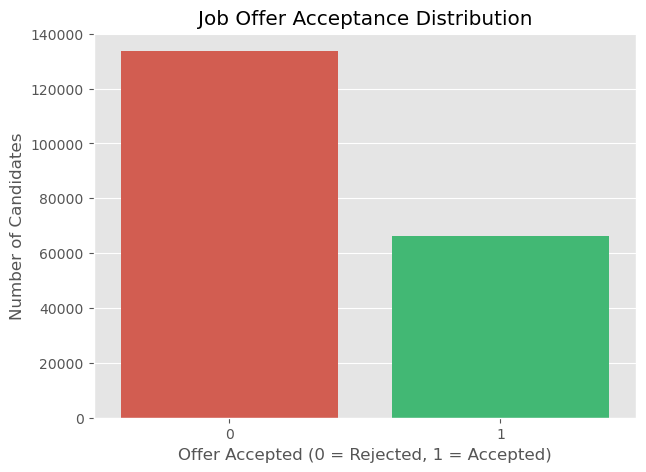

In [19]:
# 6. Target Variable Analysis
TARGET = 'offer_accepted'

print(df[TARGET].value_counts())
print('\nPercentage Distribution:')
print(df[TARGET].value_counts(normalize=True) * 100)

plt.figure(figsize=(7, 5))
sns.countplot(data=df, x=TARGET, palette=['#e74c3c', '#2ecc71'])
plt.title('Job Offer Acceptance Distribution')
plt.xlabel('Offer Accepted (0 = Rejected, 1 = Accepted)')
plt.ylabel('Number of Candidates')
plt.show()

In [20]:
# 7. Summary Statistics of Numerical Columns
df.describe()

,age,years_experience,expected_salary_usd,offered_salary_usd,company_rating,offer_accepted,salary_offer_gap_usd,offer_to_expected_salary_ratio
count,200000.000000,200000.000000,200000.000000,200000.000000,200000.000000,200000.000000,200000.00000,200000.000000
mean,37.481640,3.975783,76514.370485,80326.329305,3.753712,0.331675,3811.95882,1.049738
std,9.808264,3.862105,26630.676792,28846.742642,0.723885,0.470816,7141.54611,0.086582
min,21.000000,0.000000,16329.000000,17074.000000,2.500000,0.000000,-19132.00000,0.900000
25%,29.000000,1.200000,58070.000000,60359.000000,3.100000,0.000000,-1739.00000,0.974900
50%,37.000000,2.800000,70037.500000,73563.000000,3.800000,0.000000,3410.00000,1.049300
75%,46.000000,5.500000,88391.000000,93195.500000,4.400000,1.000000,8671.00000,1.124700
max,54.000000,20.000000,204272.000000,242460.000000,5.000000,1.000000,39373.00000,1.200000


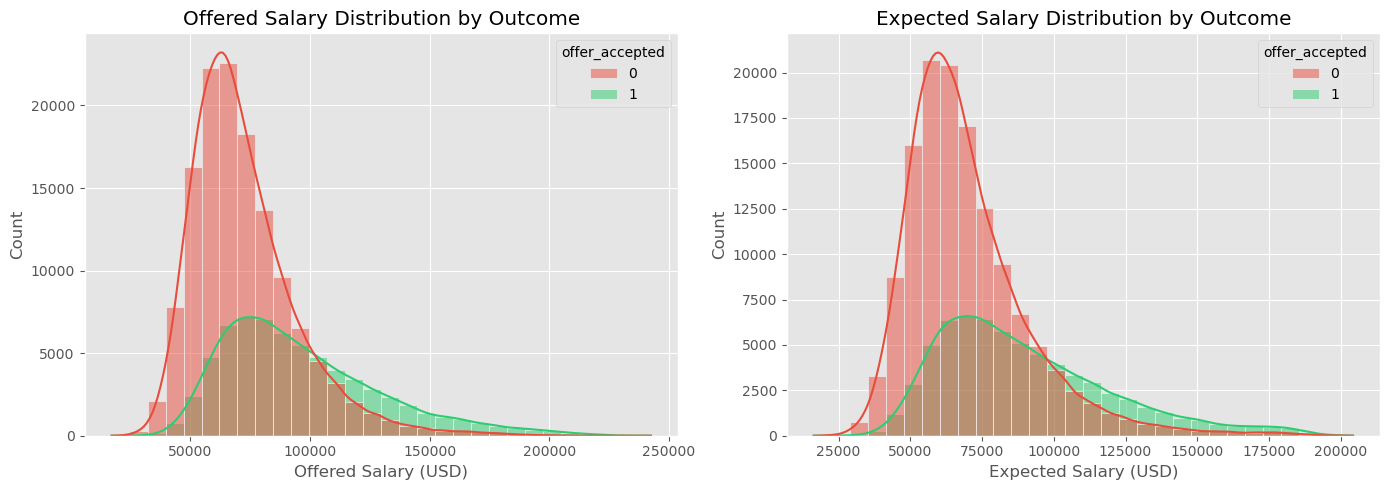

In [21]:
# 8. Salary Distribution by Target Outcome
plt.figure(figsize=(14, 5))

plt.subplot(1, 2, 1)
sns.histplot(data=df, x='offered_salary_usd', hue=TARGET, bins=30, kde=True, palette=['#e74c3c', '#2ecc71'])
plt.title('Offered Salary Distribution by Outcome')
plt.xlabel('Offered Salary (USD)')

plt.subplot(1, 2, 2)
sns.histplot(data=df, x='expected_salary_usd', hue=TARGET, bins=30, kde=True, palette=['#e74c3c', '#2ecc71'])
plt.title('Expected Salary Distribution by Outcome')
plt.xlabel('Expected Salary (USD)')

plt.tight_layout()
plt.show()

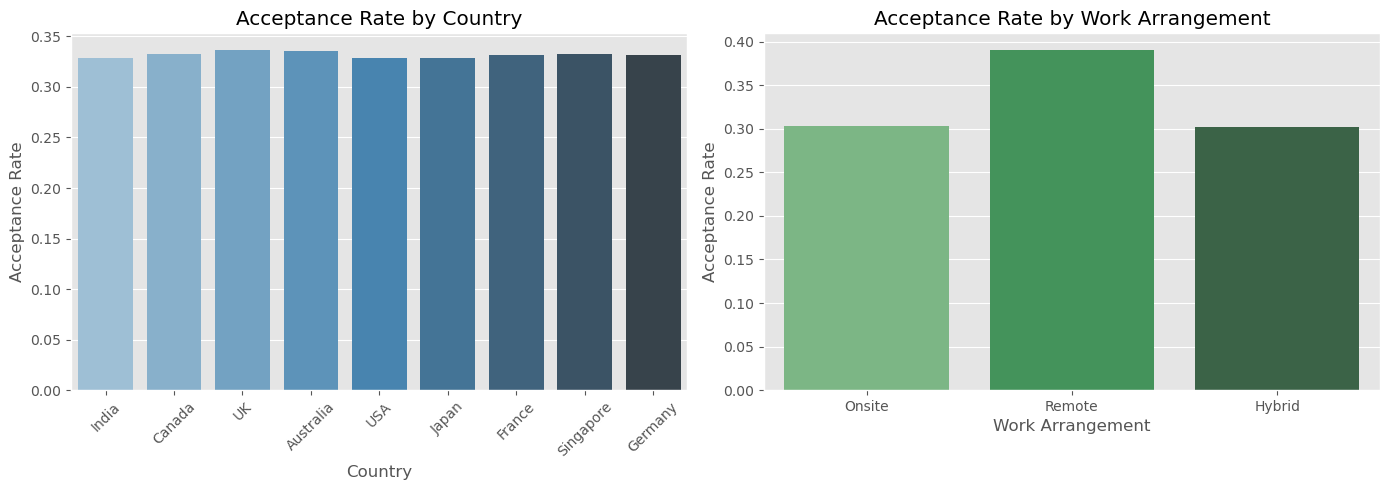

In [22]:
# 9. Offer Acceptance Rate by Country & Work Arrangement
plt.figure(figsize=(14, 5))

plt.subplot(1, 2, 1)
country_order = df['country'].value_counts().index
sns.barplot(data=df, x='country', y=TARGET, order=country_order, ci=None, palette='Blues_d')
plt.title('Acceptance Rate by Country')
plt.xlabel('Country')
plt.ylabel('Acceptance Rate')
plt.xticks(rotation=45)

plt.subplot(1, 2, 2)
sns.barplot(data=df, x='remote_preference', y=TARGET, ci=None, palette='Greens_d')
plt.title('Acceptance Rate by Work Arrangement')
plt.xlabel('Work Arrangement')
plt.ylabel('Acceptance Rate')

plt.tight_layout()
plt.show()

In [23]:
# 10. Feature Engineering (Salary Gap, Ratio, Hike %, and Experience-to-Age Ratio)
df['salary_offer_gap_usd'] = df['offered_salary_usd'] - df['expected_salary_usd']
df['offer_to_expected_salary_ratio'] = df['offered_salary_usd'] / df['expected_salary_usd'].replace(0, 1)
df['salary_hike_pct'] = (df['salary_offer_gap_usd'] / df['expected_salary_usd'].replace(0, 1)) * 100
df['exp_to_age_ratio'] = df['years_experience'] / df['age'].replace(0, 1)

print('Feature Engineering completed successfully!')
df[['salary_offer_gap_usd', 'offer_to_expected_salary_ratio', 'salary_hike_pct', 'exp_to_age_ratio']].head()

Feature Engineering completed successfully!


,salary_offer_gap_usd,offer_to_expected_salary_ratio,salary_hike_pct,exp_to_age_ratio
0,8737,1.157981,15.798134,0.014286
1,13966,1.189567,18.956741,0.079310
2,-3782,0.932356,-6.764443,0.042857
3,14368,1.182862,18.286180,0.134286
4,5840,1.113343,11.334304,0.054545


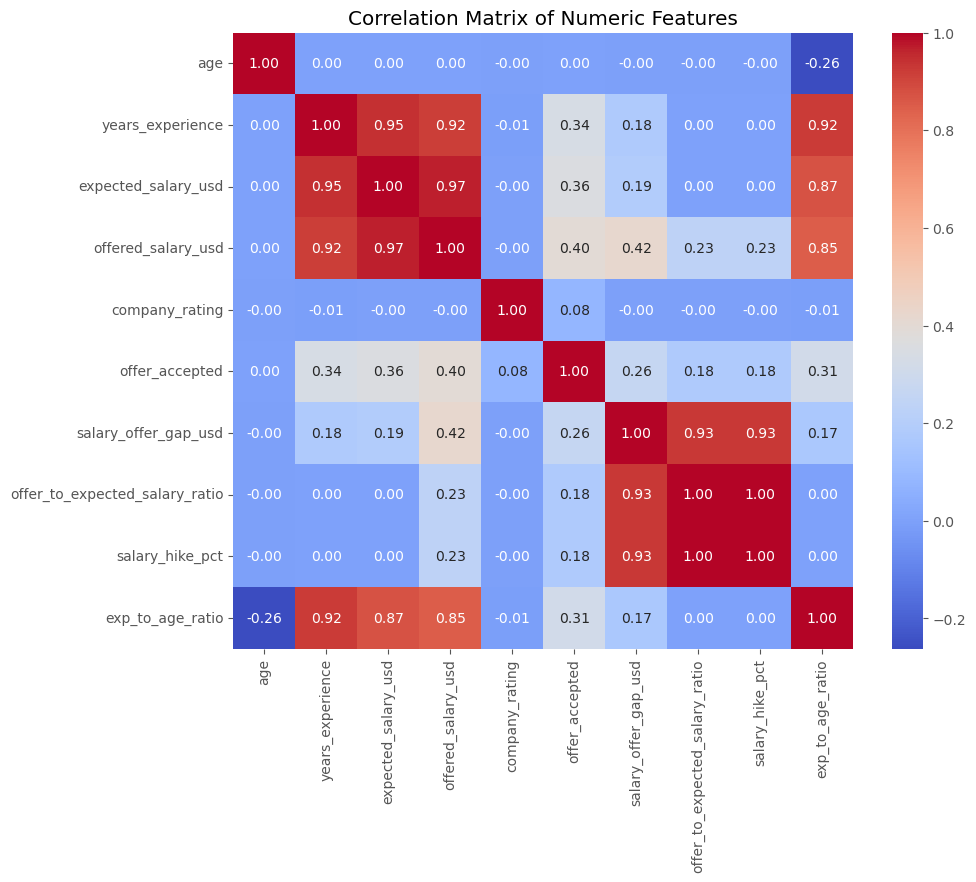

In [24]:
# 11. Correlation Heatmap
plt.figure(figsize=(10, 8))
numeric_cols = df.select_dtypes(include=[np.number]).columns
sns.heatmap(df[numeric_cols].corr(), annot=True, fmt='.2f', cmap='coolwarm', cbar=True)
plt.title('Correlation Matrix of Numeric Features')
plt.show()

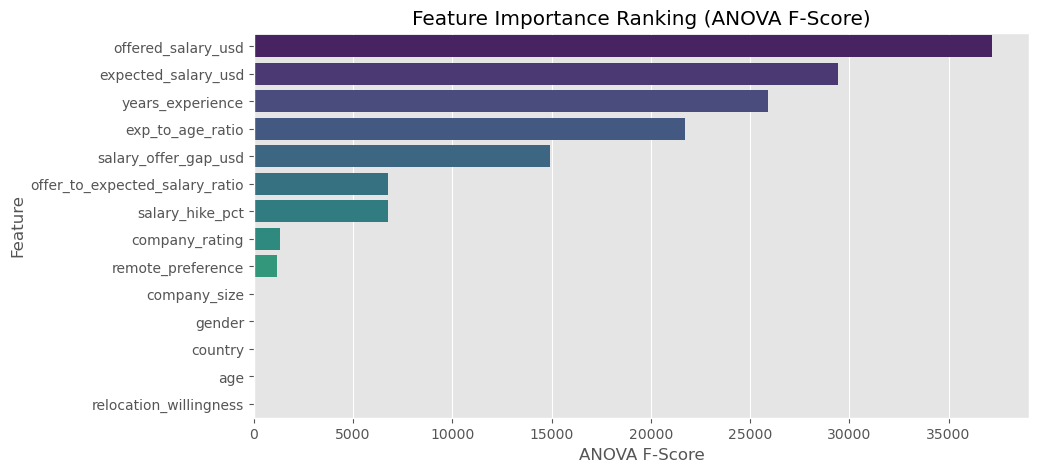

,Feature,ANOVA_F_Score
0,offered_salary_usd,37185.953795
1,expected_salary_usd,29446.099263
2,years_experience,25888.580449
3,exp_to_age_ratio,21715.076392
4,salary_offer_gap_usd,14923.033534
5,offer_to_expected_salary_ratio,6776.218297
6,salary_hike_pct,6776.218297
7,company_rating,1306.050059
8,remote_preference,1178.317076
9,company_size,2.124011


In [25]:
# 12. Feature Selection: ANOVA F-Test (SelectKBest)
X = df.drop(columns=[TARGET]).copy()
y = df[TARGET]

# Label encode categorical columns temporarily for ANOVA test
for col in X.select_dtypes(include=['object']).columns:
    X[col] = LabelEncoder().fit_transform(X[col].astype(str))

selector = SelectKBest(score_func=f_classif, k='all')
selector.fit(X, y)

feature_ranking = pd.DataFrame({
    'Feature': X.columns,
    'ANOVA_F_Score': selector.scores_
}).sort_values('ANOVA_F_Score', ascending=False).reset_index(drop=True)

plt.figure(figsize=(10, 5))
sns.barplot(data=feature_ranking, x='ANOVA_F_Score', y='Feature', palette='viridis')
plt.title('Feature Importance Ranking (ANOVA F-Score)')
plt.xlabel('ANOVA F-Score')
plt.show()

feature_ranking

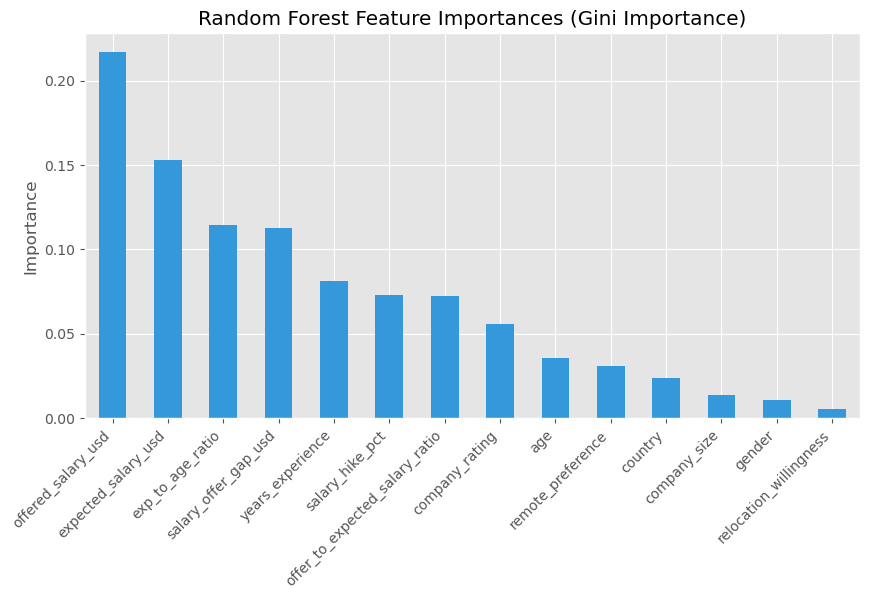

Top Features by Random Forest Importance:
offered_salary_usd                0.217282
expected_salary_usd               0.152935
exp_to_age_ratio                  0.114439
salary_offer_gap_usd              0.112844
years_experience                  0.081209
salary_hike_pct                   0.072830
offer_to_expected_salary_ratio    0.072527
company_rating                    0.055854
age                               0.035886
remote_preference                 0.030827
country                           0.023658
company_size                      0.013676
gender                            0.010555
relocation_willingness            0.005478
dtype: float64


In [26]:
# 13. Tree-Based Feature Importance (Random Forest)
# Use a fast representative sample (20,000 rows) for tree evaluation
sample_idx = np.random.RandomState(42).choice(len(X), size=20000, replace=False)
rf = RandomForestClassifier(n_estimators=50, max_depth=10, random_state=42, n_jobs=-1)
rf.fit(X.iloc[sample_idx], y.iloc[sample_idx])

rf_importances = pd.Series(rf.feature_importances_, index=X.columns).sort_values(ascending=False)

plt.figure(figsize=(10, 5))
rf_importances.plot(kind='bar', color='#3498db')
plt.title('Random Forest Feature Importances (Gini Importance)')
plt.ylabel('Importance')
plt.xticks(rotation=45, ha='right')
plt.show()

print('Top Features by Random Forest Importance:')
print(rf_importances)